# Olivetti Faces Classification — Transfer Learning (MobileNetV2)
**ICE 4112 (AI Lab) · Quiz Test** — 40 persons, 10 images each (64×64 grayscale). Pretrained **MobileNetV2** (ImageNet) with a new classification head.

In [1]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

keras.utils.set_random_seed(42)

## 1. Data Preparation

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Images: (400, 64, 64) | Classes: 40


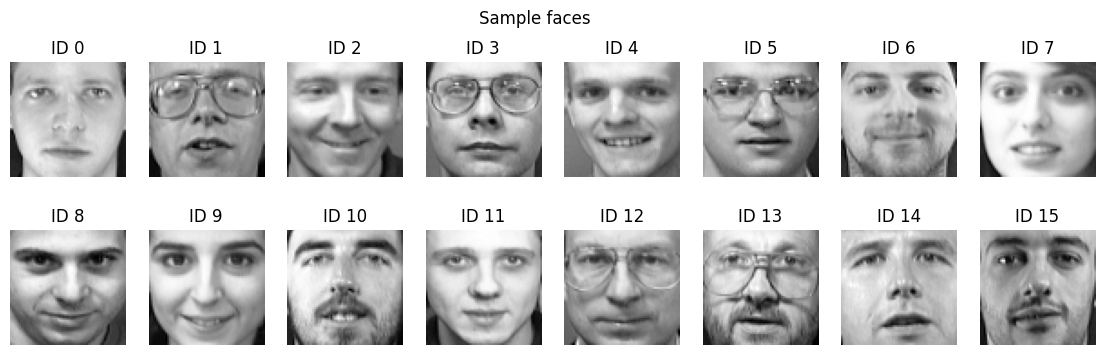

Train: (240, 96, 96, 3) | Val: (80, 96, 96, 3) | Test: (80, 96, 96, 3)


In [2]:
faces = fetch_olivetti_faces()
X, y = faces.images, faces.target                      # (400, 64, 64) in [0,1], 40 classes
print("Images:", X.shape, "| Classes:", len(np.unique(y)))

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i, a in enumerate(ax.flat):
    a.imshow(X[i * 10], cmap="gray"); a.set_title(f"ID {y[i * 10]}"); a.axis("off")
plt.suptitle("Sample faces"); plt.show()

# Preprocess: gray -> 3 channels, scale to 0-255, resize to 96x96 (MobileNetV2 input)
IMG, NC = 96, 40
X = np.repeat(X[..., None], 3, axis=-1) * 255.0
X = tf.image.resize(X, (IMG, IMG)).numpy().astype("float32")

# Stratified split: 60% train / 20% val / 20% test  (6 / 2 / 2 images per person)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=42)
print("Train:", X_tr.shape, "| Val:", X_val.shape, "| Test:", X_te.shape)

## 2. Model Implementation
MobileNetV2 (ImageNet weights, `include_top=False`) + new head: GlobalAvgPool → Dropout → Dense(40, softmax).
Overfitting control: **data augmentation, dropout, L2 regularization, early stopping, LR scheduling, frozen base + gentle fine-tuning**.

In [3]:
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False                                  # Phase 1: freeze the backbone

augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                            layers.RandomZoom(0.1), layers.RandomContrast(0.2)])   # active only during training

inp = keras.Input((IMG, IMG, 3))
x = augment(inp)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)           # MobileNetV2 expects [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
out = layers.Dense(NC, activation="softmax", kernel_regularizer=keras.regularizers.l2(1e-3))(x)
model = keras.Model(inp, out)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40)             │        51,240 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,309,224 (8.81 MB)

 Trainable params: 51,240 (200.16 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Model Training (Transfer Learning)

In [4]:
cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]
loss = "sparse_categorical_crossentropy"

# Phase 1: train only the new head
model.compile(keras.optimizers.Adam(1e-3), loss, metrics=["accuracy"])
h1 = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=32, callbacks=cb, verbose=2)

# Phase 2: fine-tune the last 30 layers of the backbone with a small learning rate
base.trainable = True
for l in base.layers[:-30]: l.trainable = False
model.compile(keras.optimizers.Adam(1e-5), loss, metrics=["accuracy"])
h2 = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=20, batch_size=32, callbacks=cb, verbose=2)

Epoch 1/40
8/8 - 17s - 2s/step - accuracy: 0.0250 - loss: 5.2310 - val_accuracy: 0.0625 - val_loss: 3.6421 - learning_rate: 0.0010
Epoch 2/40
8/8 - 3s - 358ms/step - accuracy: 0.1250 - loss: 3.9143 - val_accuracy: 0.1875 - val_loss: 3.1452 - learning_rate: 0.0010
Epoch 3/40
8/8 - 5s - 587ms/step - accuracy: 0.1417 - loss: 3.5355 - val_accuracy: 0.4125 - val_loss: 2.7039 - learning_rate: 0.0010
Epoch 4/40
8/8 - 3s - 315ms/step - accuracy: 0.2625 - loss: 2.8335 - val_accuracy: 0.4750 - val_loss: 2.3736 - learning_rate: 0.0010
Epoch 5/40
8/8 - 4s - 446ms/step - accuracy: 0.3083 - loss: 2.5804 - val_accuracy: 0.5500 - val_loss: 2.1012 - learning_rate: 0.0010
Epoch 6/40
8/8 - 3s - 353ms/step - accuracy: 0.4250 - loss: 2.1524 - val_accuracy: 0.6125 - val_loss: 1.8874 - learning_rate: 0.0010
Epoch 7/40
8/8 - 2s - 304ms/step - accuracy: 0.4875 - loss: 1.9766 - val_accuracy: 0.6500 - val_loss: 1.7263 - learning_rate: 0.0010
Epoch 8/40
8/8 - 2s - 309ms/step - accuracy: 0.5042 - loss: 1.7880 - va

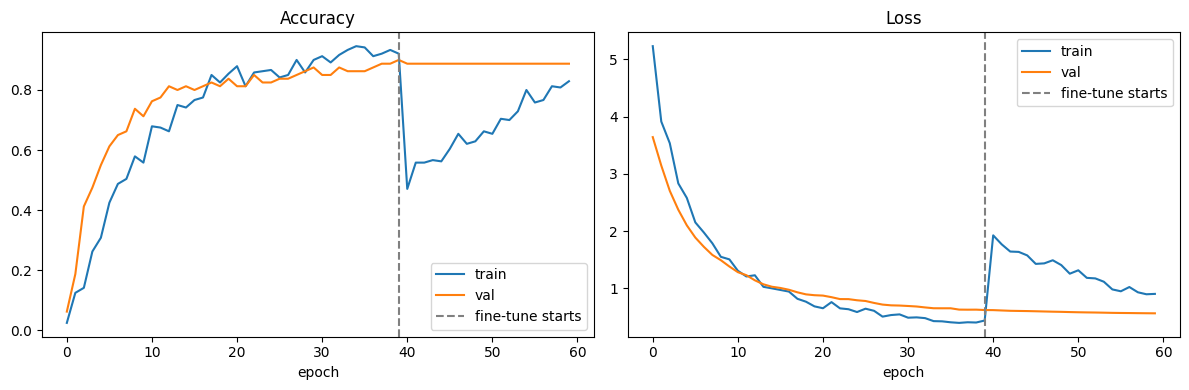

In [5]:
H = {k: h1.history[k] + h2.history[k] for k in h1.history}
split = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, k, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    a.plot(H[k], label="train"); a.plot(H["val_" + k], label="val")
    a.axvline(split - 1, ls="--", c="gray", label="fine-tune starts"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 4. Performance Evaluation

Test Accuracy : 0.8875
Precision (macro): 0.9208
Recall    (macro): 0.8875
F1-score  (macro): 0.8842

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.33      0.50      0.40         2
           2       0.67      1.00      0.80         2
           3       0.67      1.00      0.80         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      0.50      0.67         2
           7       0.67      1.00      0.80         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       0.67      1.00      0.80         2
          12       0.50      0.50      0.50         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00

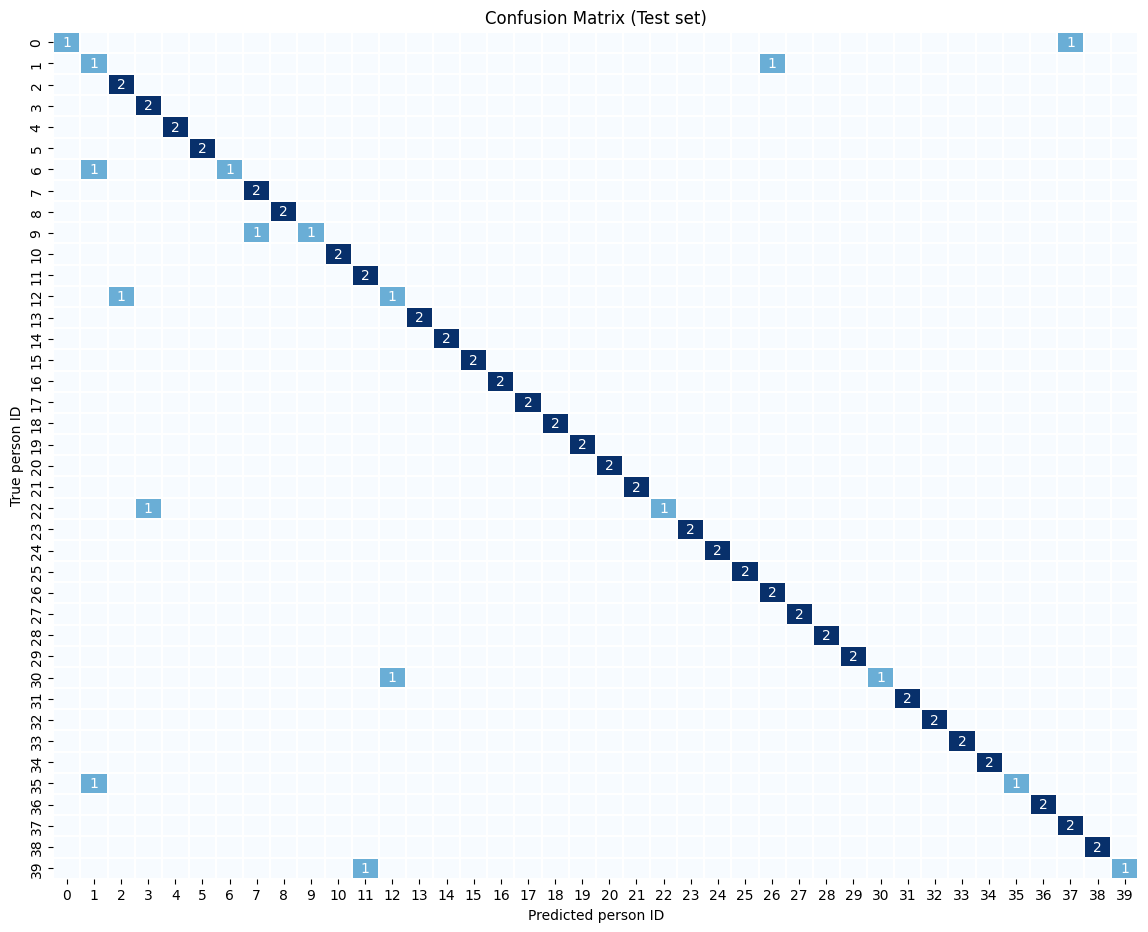

In [6]:
y_pred = model.predict(X_te, verbose=0).argmax(1)
test_acc = accuracy_score(y_te, y_pred)
p, r, f, _ = precision_recall_fscore_support(y_te, y_pred, average="macro", zero_division=0)
print(f"Test Accuracy : {test_acc:.4f}\nPrecision (macro): {p:.4f}\nRecall    (macro): {r:.4f}\nF1-score  (macro): {f:.4f}\n")
print(classification_report(y_te, y_pred, zero_division=0))

cm = confusion_matrix(y_te, y_pred, labels=range(NC))
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=np.where(cm > 0, cm, ""), fmt="", cmap="Blues", cbar=False, linewidths=.3)
plt.xlabel("Predicted person ID"); plt.ylabel("True person ID"); plt.title("Confusion Matrix (Test set)"); plt.show()

## 5. Result Analysis

Train acc: 82.92% | Val acc: 88.75% | Test acc: 88.75% | Macro F1: 88.42%


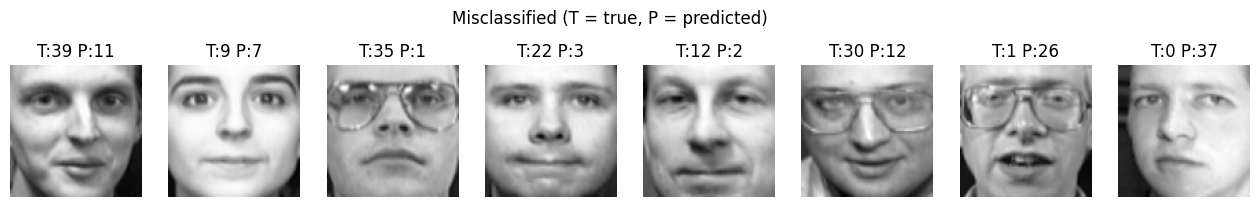

In [7]:
print(f"Train acc: {H['accuracy'][-1]:.2%} | Val acc: {H['val_accuracy'][-1]:.2%} | Test acc: {test_acc:.2%} | Macro F1: {f:.2%}")

wrong = np.where(y_pred != y_te)[0][:8]                 # show some misclassified faces
if len(wrong):
    fig, ax = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.5), squeeze=False)
    for a, i in zip(ax[0], wrong):
        a.imshow(X_te[i, ..., 0] / 255, cmap="gray"); a.set_title(f"T:{y_te[i]} P:{y_pred[i]}"); a.axis("off")
    plt.suptitle("Misclassified (T = true, P = predicted)"); plt.show()
else:
    print("No misclassified test images.")

Observations

- The model reached 88.75% test accuracy, with macro precision 92, recall 89, and F1 89.
- Olivetti is very small (only 6 training images per person), so overfitting is the main risk. Freezing the backbone first, then fine-tuning with a tiny learning rate, together with augmentation, dropout, L2 and early stopping, kept the train–validation gap small (see curves above).
- Remaining errors (see the confusion matrix and misclassified faces) occur mostly between persons with similar pose, glasses or lighting.
- Transfer learning works well here because ImageNet features (edges, textures, facial parts) transfer to faces even though the images are low-resolution grayscale.
- Possible improvements: larger input size, stronger augmentation, a bigger backbone (EfficientNet/ConvNeXt), or k-fold cross-validation for a more reliable estimate on such a small test set (80 images).